# 00 · Badminton — przegląd całej sesji
**Dane rzeczywiste:** cztery serie central/off-center z jednej rakiety, 46 automatycznych kandydatów.
To demonstracja narzędzi, nie pomiar skuteczności wykrywania wad ceramiki.

Wybierz kernel `.venv` / Ping Lab i **Run All**. Ten notebook działa samodzielnie;
nie musisz wcześniej uruchamiać pozostałych. Granice serii i zapowiedzi pochodzą
z `data/raw/badminton/session.json`. `project.json` pozostaje konfiguracją oryginalnych notebooków.
Nowe wyniki trafiają do osobnego katalogu; nagranie źródłowe pozostaje bez zmian.


In [1]:
NOTEBOOK = '00_eksploracja_do_przegladu'
from pathlib import Path
import sys, json, hashlib, io, base64
from datetime import datetime
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/pinglab').is_dir()), None)
assert ROOT is not None, 'Otwórz notebook z folderu projektu ceramic-ping-lab.'
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT/'scripts'))
%matplotlib inline
cfg = json.loads((ROOT/'data/raw/badminton/session.json').read_text())
SOURCE = ROOT/'data/raw/badminton'/cfg['audio']
assert SOURCE.is_file(), 'Brak nagrania badminton: nie przełączamy się automatycznie na demo.'
OUT = ROOT/'reports/runs/badminton-notebooks'/NOTEBOOK/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, soundfile as sf
from scipy.signal import welch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Audio, HTML, Markdown
from pinglab.audio import load_audio, Config
from pinglab.recorder import segment_ringdown, ringdown_plot
from pinglab.features import extract_features, feature_columns, decay_curve
from pinglab.learning import make_classifier
from pinglab.series import evaluate_series, paired_folds
from pinglab.embeddings import ASTEncoder
from pinglab.robustness import mix_noise

RUN_AST = False
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
colors = {'central':'#137f83', 'offcenter':'#c56838'}
r = load_audio(SOURCE, Config(sr=48000, max_seconds=180))
print('Plik:', SOURCE.name, '| SHA256:', hashlib.sha256(SOURCE.read_bytes()).hexdigest())
display(pd.DataFrame([r.qc]).drop(columns=['warnings']))
print('Uwagi QC:', r.qc['warnings'] or 'brak')

Plik: session.wav | SHA256: afc2d308b32b80ead3f80f795707a2059d2e359a33a2d6c20470464d41df7f07


,duration_s,native_sr,channels,selected_channel,peak_dbfs,rms_dbfs,clipping_fraction,dc_offset
0,88.99771,44100,1,0,-17.976912,-45.595115,0.0,8.182004e-09


Uwagi QC: ['Pasmo źródłowe kończy się przy 22050 Hz; resampling go nie odzyska']


## 1. Cztery serie, bez zapowiedzi w danych modelu
Pierwsza etykieta pochodzi z opisu nagrania. Trzy kolejne zapowiedzi potwierdzono lokalną transkrypcją: „uderzenia niecentralne, off center”, „druga seria uderzeń centralnych”, „druga seria uderzeń off center”.
Granice poniżej ustalono na przebiegu, przed modelowaniem. Odsłuchaj serie, jeśli chcesz sprawdzić trafienia.


,series_id,label,round,start_s,end_s
0,central_1,central,1,6.5,24.5
1,offcenter_1,offcenter,1,32.0,46.5
2,central_2,central,2,56.0,69.0
3,offcenter_2,offcenter,2,75.5,88.0


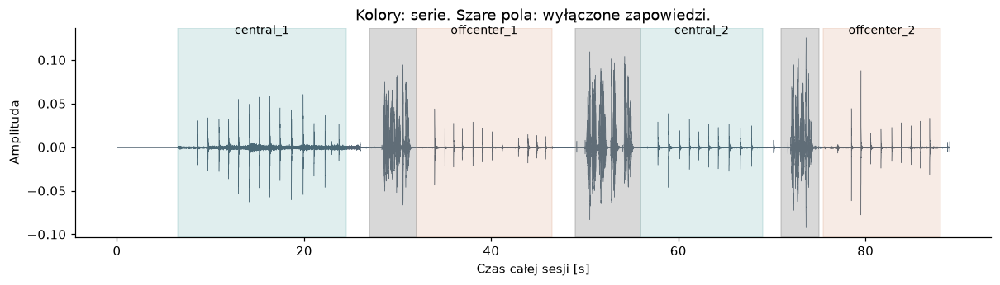

**central_1**

**offcenter_1**

**central_2**

**offcenter_2**

In [2]:
series = pd.DataFrame(cfg['series'])
display(series)
fig, ax = plt.subplots(figsize=(13,3))
step=max(1,len(r.y)//12000)
blocks=r.y[:len(r.y)//step*step].reshape(-1,step)
t=np.arange(len(blocks))*step/r.sr
ax.fill_between(t,blocks.min(1),blocks.max(1),color='#536574',lw=.3)
for s in cfg['series']:
 ax.axvspan(s['start_s'],s['end_s'],alpha=.13,color=colors[s['label']])
 ax.text((s['start_s']+s['end_s'])/2,.13,s['series_id'],ha='center',fontsize=9)
for a,b in cfg['speech_excluded_s']: ax.axvspan(a,b,color='grey',alpha=.3)
ax.set(xlabel='Czas całej sesji [s]',ylabel='Amplituda',title='Kolory: serie. Szare pola: wyłączone zapowiedzi.')
plt.show()
for s in cfg['series']:
 a,b=int(s['start_s']*r.sr),int(s['end_s']*r.sr)
 display(Markdown('**'+s['series_id']+'**'))
 display(Audio(r.y[a:b],rate=r.sr,normalize=False))
 sf.write(OUT/(s['series_id']+'.wav'),r.y[a:b],r.sr,subtype='PCM_24')

## 2. Uderzenie i wybrzmienie
Detektor szuka nagłych zmian widma wyłącznie wewnątrz serii. Nie wymuszamy dziesięciu wykryć.
Czerwony pas to umowne pierwsze 30 ms, zielony — obserwowany spadek do progu tła, pomarańczowy — brak takiego spadku przed następnym zdarzeniem. **To heurystyka, nie pomiar fizycznego czasu tłumienia.** Zmiana tła również może dać pomarańczową flagę.

Model dostaje jednakowe okno: 25 ms przed początkiem + 350 ms po nim, skrócone przed kolejnym uderzeniem. Nie uczymy modelu na długości ręcznie wyciętego klipu.


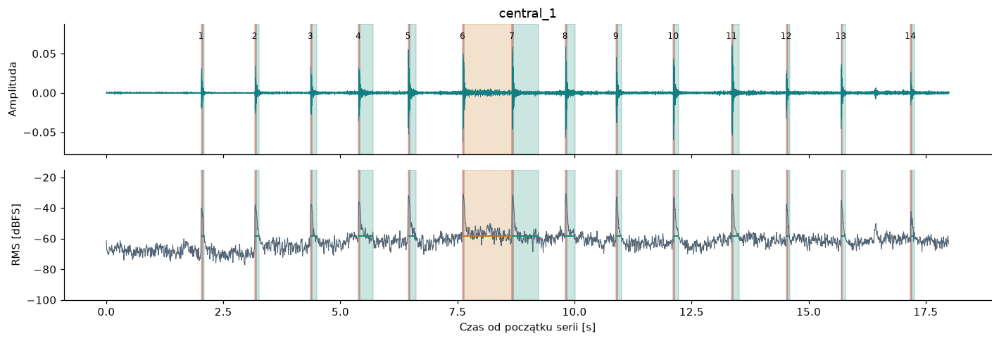

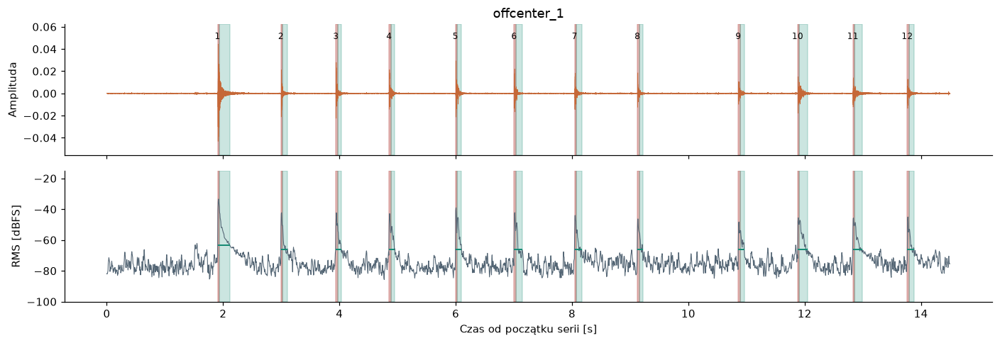

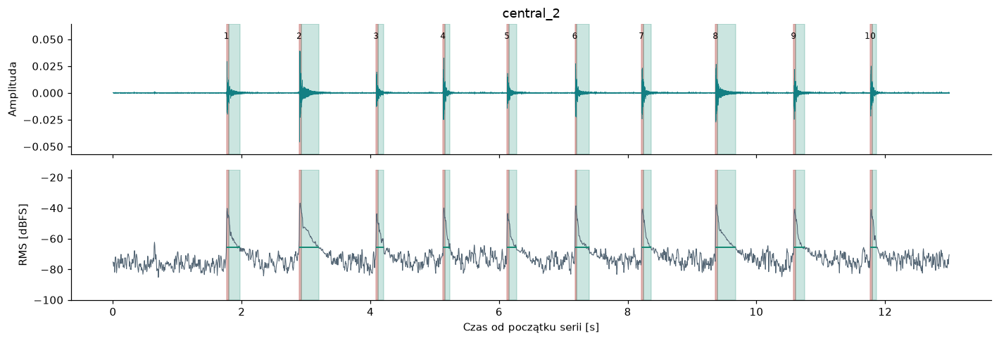

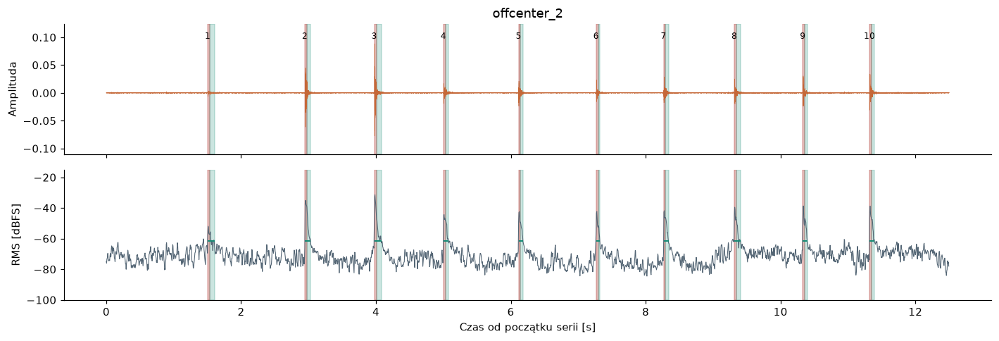

,,uderzenia,szczyt_mediana_dbfs,niepewne
series_id,label,,,
central_1,central,14,-26.799461,0
offcenter_1,offcenter,12,-34.025085,0
central_2,central,10,-31.644835,0
offcenter_2,offcenter,10,-31.444176,1


,event_id,onset_s,ringdown_s,ringdown_status,uncertain
0,central_1_01,8.525,0.070,zanik zaobserwowany,False
1,central_1_02,9.670,0.100,zanik zaobserwowany,False
2,central_1_03,10.860,0.140,zanik zaobserwowany,False
3,central_1_04,11.885,0.315,zanik zaobserwowany,False
4,central_1_05,12.945,0.170,zanik zaobserwowany,False
5,central_1_06,14.110,1.055,kolejne uderzenie przed zanikiem,False
6,central_1_07,15.165,0.570,zanik zaobserwowany,False
7,central_1_08,16.300,0.215,zanik zaobserwowany,False
8,central_1_09,17.385,0.120,zanik zaobserwowany,False
9,central_1_10,18.610,0.115,zanik zaobserwowany,False


In [3]:
rows=[]; clips={}; series_traces={}
for s in cfg['series']:
 z=r.y[int(s['start_s']*r.sr):int(s['end_s']*r.sr)]
 tab,t,db=segment_ringdown(z,r.sr,**cfg['detector'])
 series_traces[s['series_id']]=(z,tab,t,db)
 interactive=ringdown_plot(z,r.sr,tab,t,db)
 interactive.write_html(OUT/(s['series_id']+'_segmentacja.html'),include_plotlyjs=True)
 fig,axes=plt.subplots(2,1,figsize=(13,4.5),sharex=True)
 axes[0].plot(np.arange(len(z))/r.sr,z,lw=.4,color=colors[s['label']])
 axes[1].plot(t,db,lw=.7,color='#536574')
 for k,row in enumerate(tab.itertuples()):
  onset=float(row.onset_s);absolute=s['start_s']+onset
  a=max(0,onset-cfg['pre_s'])
  nxt=float(tab.iloc[k+1].onset_s) if k+1<len(tab) else len(z)/r.sr
  b=min(onset+cfg['feature_tail_s'],nxt-.015,len(z)/r.sr)
  clip=z[int(a*r.sr):int(b*r.sr)]
  eid=f"{s['series_id']}_{k+1:02d}"
  clips[eid]=clip
  uncertain=any(abs(absolute-v)<.05 for v in cfg['uncertain_onsets_s'])
  rows.append(dict(event_id=eid,series_id=s['series_id'],round=s['round'],label=s['label'],
   onset_s=absolute,offset_s=onset-a,window_s=len(clip)/r.sr,
   ringdown_s=row.duration_s,ringdown_status=row.status,uncertain=uncertain,
   peak_dbfs=20*np.log10(max(abs(clip).max(),1e-12)),
   **extract_features(clip,r.sr,onset-a,cfg['fmax'])))
  shade='#c47817' if 'przed zanikiem' in row.status else '#168b75'
  for ax in axes:
   ax.axvspan(onset,row.attack_end_s,color='#b4423e',alpha=.35)
   ax.axvspan(row.attack_end_s,row.end_s,color=shade,alpha=.22)
  axes[0].text(onset,abs(z).max()*1.1,str(k+1),fontsize=8,ha='center')
  axes[1].hlines(row.threshold_dbfs,onset,row.end_s,color=shade,lw=1.3)
 axes[0].set(title=s['series_id'],ylabel='Amplituda',ylim=(-abs(z).max()*1.25,abs(z).max()*1.4))
 axes[1].set(xlabel='Czas od początku serii [s]',ylabel='RMS [dBFS]',ylim=(-100,-15))
 plt.tight_layout();plt.show()
events=pd.DataFrame(rows)
events.to_csv(OUT/'features.csv',index=False)
display(events.groupby(['series_id','label'],sort=False).agg(uderzenia=('event_id','size'),
 szczyt_mediana_dbfs=('peak_dbfs','median'),niepewne=('uncertain','sum')))
display(events[['event_id','onset_s','ringdown_s','ringdown_status','uncertain']])
assert all(not (a<=v<=b) for v in events.onset_s for a,b in cfg['speech_excluded_s'])
assert events.window_s.min()>.05

## 3. Odsłuch i widma
Każde zdarzenie zachowuje czas w całym nagraniu. Etykieta pochodzi z serii; nie potwierdza, że każde pojedyncze trafienie rzeczywiście było centralne lub niecentralne.
Zdarzenie około 77 s jest znacznie słabsze i pozostaje oznaczone jako niepewne. Poniżej można odsłuchać wszystkie wykrycia.


central_1_01,8.525 s,etykieta serii,
central_1_02,9.670 s,etykieta serii,
central_1_03,10.860 s,etykieta serii,
central_1_04,11.885 s,etykieta serii,
central_1_05,12.945 s,etykieta serii,
central_1_06,14.110 s,etykieta serii,
central_1_07,15.165 s,etykieta serii,
central_1_08,16.300 s,etykieta serii,
central_1_09,17.385 s,etykieta serii,
central_1_10,18.610 s,etykieta serii,
central_1_11,19.855 s,etykieta serii,


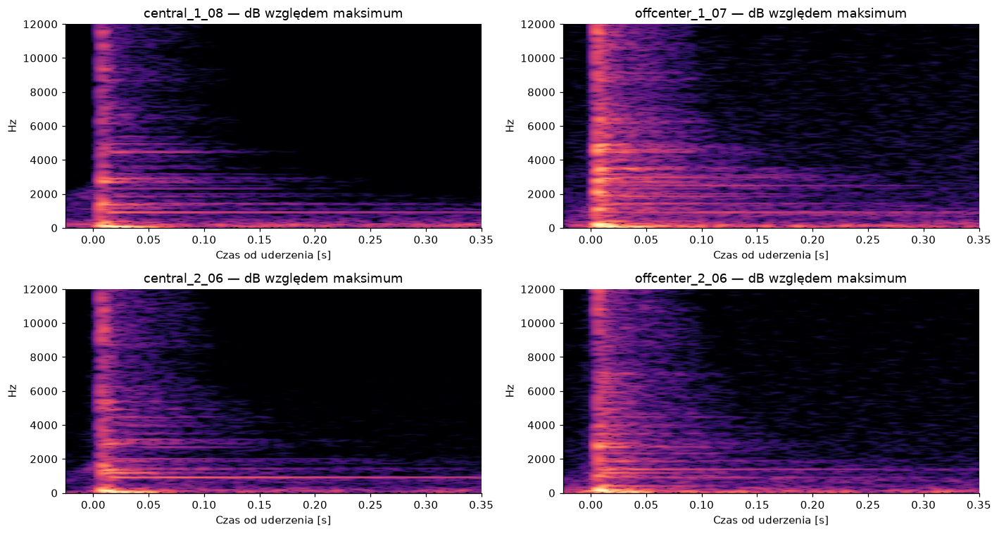

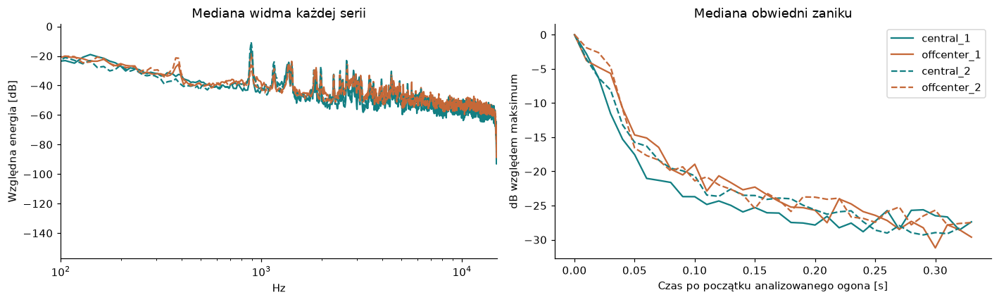

In [4]:
audio_rows=[]
for row in events.itertuples():
 signal=clips[row.event_id]
 buffer=io.BytesIO();sf.write(buffer,signal,r.sr,format='WAV',subtype='PCM_16')
 audio_rows.append(f'<tr><td>{row.event_id}</td><td>{row.onset_s:.3f} s</td><td>{"do sprawdzenia" if row.uncertain else "etykieta serii"}</td><td><audio controls preload="none" src="data:audio/wav;base64,{base64.b64encode(buffer.getvalue()).decode()}"></audio></td></tr>')
display(HTML('<details><summary>Odsłuch wszystkich uderzeń</summary><table>'+''.join(audio_rows)+'</table></details>'))
fig,axes=plt.subplots(2,2,figsize=(13,7))
for ax,s in zip(axes.flat,cfg['series']):
 ids=events.loc[events.series_id==s['series_id'],'event_id'].tolist()
 clip=clips[ids[len(ids)//2]]
 spec=librosa.amplitude_to_db(abs(librosa.stft(clip,n_fft=1024,hop_length=110)),ref=np.max)
 ax.imshow(spec,origin='lower',aspect='auto',extent=[-.025,len(clip)/r.sr-.025,0,r.sr/2],vmin=-70,vmax=0,cmap='magma')
 ax.set(title=ids[len(ids)//2]+' — dB względem maksimum',xlabel='Czas od uderzenia [s]',ylabel='Hz',ylim=(0,12000))
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4))
for s in cfg['series']:
 spectra=[];decays=[]
 for eid in events.loc[events.series_id==s['series_id'],'event_id']:
  clip=clips[eid];f,p=welch(clip[int(.035*r.sr):],fs=r.sr,nperseg=4096)
  spectra.append(p/max(p.sum(),1e-20))
  tt,d=decay_curve(clip,r.sr);decays.append(d)
 med=np.median(spectra,axis=0)
 axes[0].plot(f,10*np.log10(med+1e-15),label=s['series_id'],color=colors[s['label']],ls='-' if s['round']==1 else '--')
 common=min(map(len,decays))
 axes[1].plot(tt[:common],np.median([d[:common] for d in decays],axis=0),label=s['series_id'],color=colors[s['label']],ls='-' if s['round']==1 else '--')
axes[0].set(xlim=(100,15000),xlabel='Hz',ylabel='Względna energia [dB]',title='Mediana widma każdej serii');axes[0].set_xscale('log')
axes[1].set(xlabel='Czas po początku analizowanego ogona [s]',ylabel='dB względem maksimum',title='Mediana obwiedni zaniku');axes[1].legend()
plt.tight_layout();plt.show()

## 4. Reprezentacja cech
Porównujemy rezonans (3 cechy), cechy fizyczne (15), MFCC i mel. Amplituda jest normalizowana przed ekstrakcją; osobno sprawdzamy, ile można odgadnąć z samej głośności.
PCA poniżej służy tylko do oglądania danych. Zostało dopasowane do wszystkich punktów i **nie jest testem skuteczności**. Kształt punktu oznacza rundę.


peak_hz         centroid_hz         decay10_s        peak_dbfs  \
             median     std      median     std    median   std     median   
series_id                                                                    
central_1    890.62  310.10      962.14  270.53      0.03  0.01 -26.799999   
central_2    890.62  244.58     1298.40  511.77      0.04  0.01 -31.639999   
offcenter_1  380.86  439.71     1349.17  244.15      0.04  0.02 -34.029999   
offcenter_2  638.67  553.61     1323.38  581.23      0.04  0.01 -31.440001   

                   
              std  
series_id          
central_1    2.62  
central_2    2.24  
offcenter_1  3.33  
offcenter_2  6.03

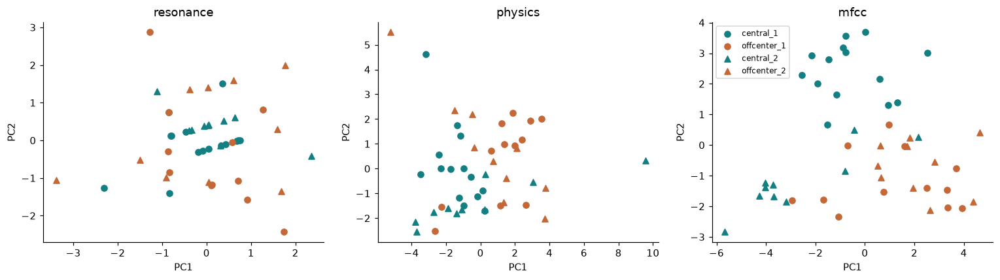

In [5]:
display(events.groupby('series_id')[['peak_hz','centroid_hz','decay10_s','peak_dbfs']].agg(['median','std']).round(2))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,family in zip(axes,['resonance','physics','mfcc']):
 x=StandardScaler().fit_transform(events[feature_columns(events,family)])
 xy=PCA(2).fit_transform(x)
 for s in cfg['series']:
  mask=events.series_id==s['series_id']
  ax.scatter(xy[mask,0],xy[mask,1],label=s['series_id'],c=colors[s['label']],marker='o' if s['round']==1 else '^')
 ax.set(title=family,xlabel='PC1',ylabel='PC2')
axes[-1].legend(fontsize=8);plt.tight_layout();plt.show()

## 5. Klasyfikacja i odległość od centralnych wzorców
Dwie próby: uczymy na seriach 1–2 i sprawdzamy 3–4, potem odwrotnie. Skalowanie i model uczą się tylko na części treningowej. Używamy ustalonej regresji logistycznej (`C=0.1`), bez poszukiwania najlepszego parametru.

Odległość pyta: „jak daleko ten dźwięk leży od centralnych uderzeń treningowych?”. Próg pochodzi wyłącznie z odległości między wzorcami treningowymi, ale nie jest skalibrowany. AUC ocenia kolejność wyników bez progu; balanced accuracy uśrednia trafność obu klas.

**Dwie rundy jednej sesji nie wystarczają do wiarygodnej oceny generalizacji.** Uderzenia są skorelowane; nie liczymy przedziałów ufności tak, jakby były niezależnymi obiektami. Porównanie wielu metod jest eksploracyjne.


,fold,train_series,test_series
0,1,"[central_2, offcenter_2]","[central_1, offcenter_1]"
1,2,"[central_1, offcenter_1]","[central_2, offcenter_2]"


,family,method,test_round,n_test,balanced_accuracy,auc,central_recall,offcenter_recall
0,loudness,logistic,1,26,0.161,0.048,0.071,0.250
1,loudness,logistic,2,20,0.400,0.470,0.200,0.600
2,resonance,logistic,1,26,0.286,0.185,0.071,0.500
3,resonance,logistic,2,20,0.450,0.470,0.400,0.500
4,resonance,distance,1,26,0.500,0.804,1.000,0.000
5,resonance,distance,2,20,0.450,0.630,0.900,0.000
6,physics,logistic,1,26,0.482,0.470,0.214,0.750
7,physics,logistic,2,20,0.550,0.570,0.400,0.700
8,physics,distance,1,26,0.512,0.583,0.857,0.167
9,physics,distance,2,20,0.550,0.690,0.800,0.300


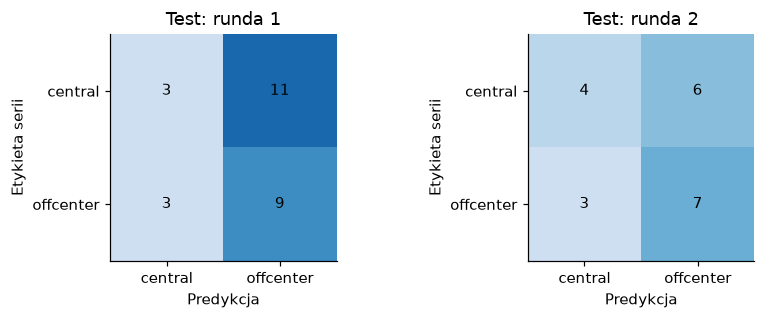

,event_id,series_id,label,fold,family,method,score,threshold,prediction,onset_s,uncertain
0,central_1_01,central_1,central,1,physics,logistic,0.565443,0.5,offcenter,8.525,False
1,central_1_02,central_1,central,1,physics,logistic,0.637992,0.5,offcenter,9.670,False
2,central_1_03,central_1,central,1,physics,logistic,0.512763,0.5,offcenter,10.860,False
3,central_1_05,central_1,central,1,physics,logistic,0.642296,0.5,offcenter,12.945,False
4,central_1_06,central_1,central,1,physics,logistic,0.624368,0.5,offcenter,14.110,False
5,central_1_07,central_1,central,1,physics,logistic,0.580101,0.5,offcenter,15.165,False
6,central_1_08,central_1,central,1,physics,logistic,0.572858,0.5,offcenter,16.300,False
7,central_1_09,central_1,central,1,physics,logistic,0.612724,0.5,offcenter,17.385,False
8,central_1_12,central_1,central,1,physics,logistic,0.714799,0.5,offcenter,21.020,False
9,central_1_13,central_1,central,1,physics,logistic,0.606400,0.5,offcenter,22.190,False


In [6]:
metrics=[];predictions=[]
for family in ['loudness','resonance','physics','mfcc','mel']:
 for method in (['logistic'] if family=='loudness' else ['logistic','distance']):
  m,p,audit=evaluate_series(events,family,method)
  metrics.append(m);predictions.append(p)
(OUT/'fold_audit.json').write_text(json.dumps(audit,indent=2))
display(pd.DataFrame(audit))
metrics=pd.concat(metrics,ignore_index=True);predictions=pd.concat(predictions,ignore_index=True)
display(metrics[['family','method','test_round','n_test','balanced_accuracy','auc','central_recall','offcenter_recall']].round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,row in zip(axes,metrics.query("family=='physics' and method=='logistic'").itertuples()):
 cm=np.array(row.confusion_matrix);ax.imshow(cm,cmap='Blues',vmin=0,vmax=14)
 for i in range(2):
  for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
 ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['central','offcenter'],yticklabels=['central','offcenter'],xlabel='Predykcja',ylabel='Etykieta serii',title=f'Test: runda {row.test_round}')
plt.tight_layout();plt.show()
errors=predictions.query("family=='physics' and method=='logistic' and label!=prediction")
display(errors.merge(events[['event_id','onset_s','uncertain']],on='event_id'))

## Wniosek do pokazania
W pierwszej serii centralnej widać zmianę głośności między rundami. Proste modele mają niestabilne wyniki. Nie utożsamiamy pojedynczych uderzeń z niezależnymi rakietami. Kolejne widoki: 01 — para A/B, 02 — ręczna korekta, 04 — AST, 05 — szum, 06 — porównanie modeli, 07 — interaktywne wybrzmienia.

In [7]:
print('GOTOWE:', NOTEBOOK, '| pliki wynikowe:', OUT)

GOTOWE: 00_eksploracja_do_przegladu | pliki wynikowe: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/badminton-notebooks/00_eksploracja_do_przegladu/20260928_144849_988682
